# Q2: Effect of Training Data Size

In [12]:
import sys
from pathlib import Path
import time

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.base import clone

In [13]:
# shared project folder
project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

sys.path.insert(0, str(project_dir))

from data_utils import load_data, split_data

# load same dataset and validation split
zip_path = project_dir / "data" / "cornell-tech-cs-5785-combined-2026-ai-vs-human-text.zip"

train, unlabeled, test = load_data(zip_path)
train_df, val_df = split_data(train)

# define tuned model used for Q2
model_a = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 3),
        min_df=5,
        max_features=50000
    )),
    ("logreg", LogisticRegression(
        C=10.0,
        max_iter=1000,
        random_state=42
    ))
])

## Q2.1: Training and validation AUROC

In [14]:
# training sizes required by Q2.1
training_sizes = [500, 1000, 2000, 5000, 8000]
learning_curve_results = []

for n in training_sizes:
    # sample n examples from og training partition
    # stratify to maintain 50/50 human/AI label balance
    if n == len(train_df):
        subset = train_df.copy()
    else:
        subset, _ = train_test_split(
            train_df,
            train_size=n,
            stratify=train_df["label"],
            random_state=42
        )

    # create fresh model using best hyperparams
    model = clone(model_a)
    model.set_params(
        tfidf__ngram_range=(1, 3),
        tfidf__min_df=5,
        logreg__C=10.0
    )

    # train on only selected subset
    start_time = time.perf_counter()
    model.fit(subset["text"], subset["label"])
    elapsed = time.perf_counter() - start_time

    # calc training and validation AUROC
    train_probs = model.predict_proba(subset["text"])[:, 1]
    val_probs = model.predict_proba(val_df["text"])[:, 1]

    train_auc = roc_auc_score(subset["label"], train_probs)
    val_auc = roc_auc_score(val_df["label"], val_probs)

    # store results for report
    learning_curve_results.append({
        "Training rows": n,
        "Train AUROC": train_auc,
        "Validation AUROC": val_auc,
        "Train time (s)": elapsed
    })

    print(f"Finished {n} rows: Train AUROC = {train_auc:.4f}, "
          f"Val AUROC = {val_auc:.4f}")

# display
learning_curve_df = pd.DataFrame(learning_curve_results)
learning_curve_df.round(4)

Finished 500 rows: Train AUROC = 1.0000, Val AUROC = 0.8517
Finished 1000 rows: Train AUROC = 1.0000, Val AUROC = 0.8904
Finished 2000 rows: Train AUROC = 1.0000, Val AUROC = 0.9082
Finished 5000 rows: Train AUROC = 1.0000, Val AUROC = 0.9280
Finished 8000 rows: Train AUROC = 1.0000, Val AUROC = 0.9357


,Training rows,Train AUROC,Validation AUROC,Train time (s)
0,500,1.0,0.8517,0.4719
1,1000,1.0,0.8904,1.3549
2,2000,1.0,0.9082,2.4364
3,5000,1.0,0.9280,5.9934
4,8000,1.0,0.9357,9.6483


## Q2.2: Learning Curve

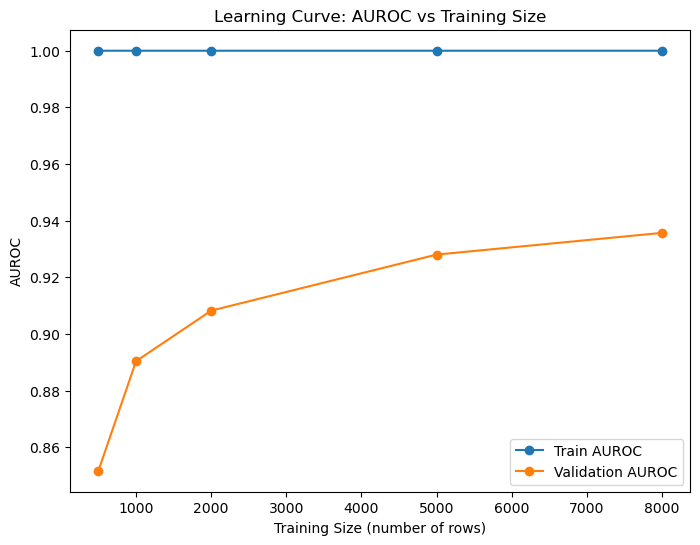

In [15]:
# plot training + validation AUROC vs training size
plt.figure(figsize=(8, 6))
plt.plot(learning_curve_df["Training rows"], learning_curve_df["Train AUROC"], marker='o', label='Train AUROC')
plt.plot(learning_curve_df["Training rows"], learning_curve_df["Validation AUROC"], marker='o', label='Validation AUROC')
plt.title('Learning Curve: AUROC vs Training Size')
plt.xlabel('Training Size (number of rows)')
plt.ylabel('AUROC')
plt.legend() 
plt.show()   

## Q2.3: Learning curve explanation (written in report)